# TTA data exploration: Rth at the start and end of the thermal-shock test

## Where the data comes from
- Source: `data/raw/TTA/TTA/<LED type>/`. These are the **processed** transient thermal analysis (TTA) curves of the Schmid et al. study (IEEE T-DMR 22(2), 2022, `docs/reference_papers`). They are not the instrument files in `data/raw/TTA-Raw`.
- 9 LED types (FC-SP1..4, FC-GB1..3, VTF1..2) x 5 solder pastes x 4 panels x 10 LEDs = 1800 LEDs, each measured at 12 thermal-shock cycle counts (0, 25, 50, 100, 150, 250, 350, 500, 750, 1000, 1250, 1500) -> 21,600 files.
- **File name:** `TTA_<LED type>_<paste>_<panel>_<LED no.>_<cycles>TSC.dat`, e.g. `TTA_FC-GB3_SAC105_1_1_1500TSC.dat` = FC-GB3, SAC105 paste, panel 1, LED 1, after 1500 thermal shock cycles (TSC).
- **File content:** whitespace-separated columns `t  z  Vf  Zth  B` where `t` is time in s (about 0.8 us to 1.95 s, 256 log-spaced points), `z = ln(t)`, `Vf` is the forward-voltage change, `Zth` is the thermal impedance in K/W and `B` is another derived column (not used here).
- **`.err` files** have only the header line. They replace the `.dat` for a measurement that failed or was rejected. Those LEDs have no curve at that cycle count.

## How Rth is obtained
Following the paper (Eq. 1-4), Rth is the **terminal value of the thermal impedance curve**, Zth(t -> infinity), the plateau where the LED is in thermal equilibrium. Here Rth is the mean of the **last 5 points** of the Zth curve (t of about 1.5 to 1.95 s), which reduces noise at the end of the curve. The *start* is the 0-cycle file and the *end* is the 1500-cycle file of the same LED. The increase is `Rth_end - Rth_start`, also given in %.

Check: the 0-cycle averages should match the paper's Table V (Rth of about 6 to 10.6 K/W by LED type).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/raw/TTA/TTA")
START, END = 0, 1500          # thermal shock cycles
N_TAIL = 5                    # points averaged for the plateau value

NAME = re.compile(r"TTA_(?P<led_type>[^_]+)_(?P<paste>[^_]+)_(?P<panel>\d+)_(?P<led>\d+)_(?P<cycles>\d+)TSC\.(?P<ext>dat|err)$")

def inventory():
    rows = []
    for p in DATA.rglob("*"):
        m = NAME.match(p.name)
        if m:
            d = m.groupdict()
            d.update(panel=int(d["panel"]), led=int(d["led"]), cycles=int(d["cycles"]), path=p)
            rows.append(d)
    return pd.DataFrame(rows)

inv = inventory()
print(len(inv), "files;", (inv.ext == "err").sum(), "are .err (no curve)")
inv.groupby(["led_type", "ext"]).size().unstack(fill_value=0)

21600 files; 3437 are .err (no curve)


ext,dat,err
led_type,,
FC-GB1,0,2400
FC-GB2,1820,580
FC-GB3,2336,64
FC-SP1,2339,61
FC-SP2,2339,61
FC-SP3,2316,84
FC-SP4,2333,67
VTF1,2340,60
VTF2,2340,60


In [2]:
def load_curve(path):
    # columns: t, z, Vf, Zth, B  (header line starts with '#')
    return pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["t", "z", "Vf", "Zth", "B"])

def rth(path, n_tail=N_TAIL):
    # Rth = plateau of Zth(t): mean of the last n_tail points
    return load_curve(path)["Zth"].tail(n_tail).mean()

dat = inv[(inv.ext == "dat") & inv.cycles.isin([START, END])].copy()
dat["rth"] = dat["path"].map(rth)

key = ["led_type", "paste", "panel", "led"]
wide = dat.pivot_table(index=key, columns="cycles", values="rth").rename(columns={START: "rth_start", END: "rth_end"})
wide["rth_increase"] = wide.rth_end - wide.rth_start
wide["rth_increase_pct"] = 100 * wide.rth_increase / wide.rth_start
wide = wide.reset_index()
print(len(wide), "LEDs;", wide[["rth_start", "rth_end"]].isna().any(axis=1).sum(), "missing start or end (.err)")
wide.head()

1559 LEDs; 177 missing start or end (.err)


cycles,led_type,paste,panel,led,rth_start,rth_end,rth_increase,rth_increase_pct
0,FC-GB2,SAC107-BiIn,1,2,9.574936,29.839828,20.264891,211.645181
1,FC-GB2,SAC107-BiIn,1,3,9.575680,16.605415,7.029735,73.412388
2,FC-GB2,SAC107-BiIn,1,4,9.613354,14.151400,4.538046,47.205646
3,FC-GB2,SAC107-BiIn,1,5,9.537545,16.517620,6.980075,73.185239
4,FC-GB2,SAC107-BiIn,1,6,9.422192,17.237209,7.815018,82.942673


In [3]:
summary = (wide.dropna().groupby("led_type")
           .agg(n=("rth_start", "size"), start=("rth_start", "mean"), end=("rth_end", "mean"),
                inc=("rth_increase", "mean"), inc_pct=("rth_increase_pct", "mean")).round(2))
summary   # compare 'start' with Table V of the paper

,n,start,end,inc,inc_pct
led_type,,,,,
FC-GB2,124,9.49,1.266020e+11,1.266020e+11,1.311445e+12
FC-GB3,179,10.30,3.032000e+01,2.002000e+01,1.938900e+02
FC-SP1,180,10.66,1.111000e+01,4.500000e-01,4.230000e+00
FC-SP2,180,6.17,1.203000e+01,5.860000e+00,9.526000e+01
FC-SP3,180,7.43,1.275000e+01,5.320000e+00,7.168000e+01
FC-SP4,179,8.92,1.529000e+01,6.380000e+00,7.148000e+01
VTF1,180,6.73,7.030000e+00,3.000000e-01,4.400000e+00
VTF2,180,8.41,1.765000e+01,9.240000e+00,1.102300e+02


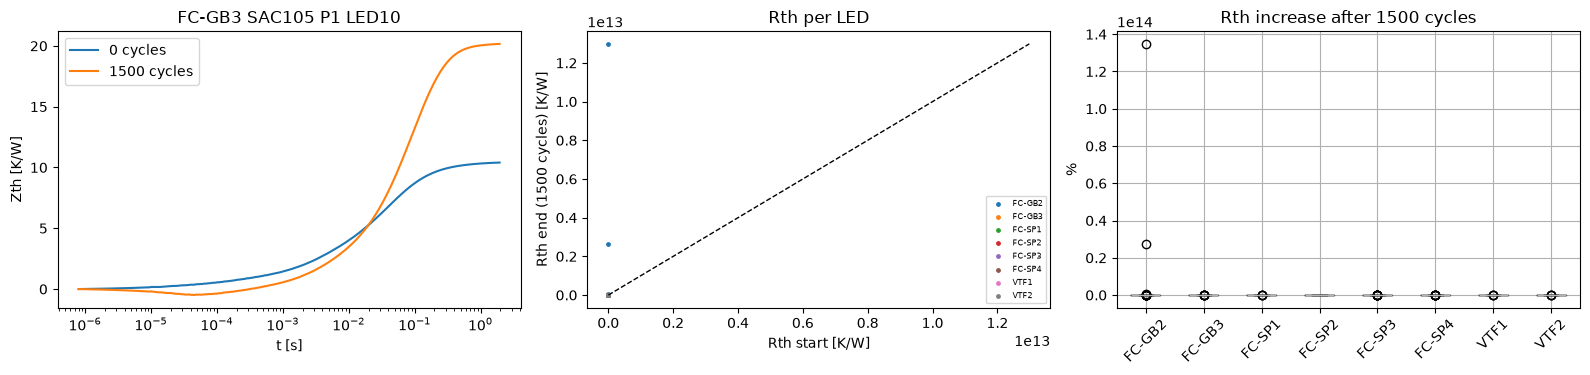

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
# example curves for one LED
for c in (START, END):
    r = inv[(inv.led_type == "FC-GB3") & (inv.paste == "SAC105") & (inv.panel == 1) & (inv.led == 10) & (inv.cycles == c)].iloc[0]
    cur = load_curve(r.path); ax[0].semilogx(cur.t, cur.Zth, label=f"{c} cycles")
ax[0].set(xlabel="t [s]", ylabel="Zth [K/W]", title="FC-GB3 SAC105 P1 LED10"); ax[0].legend()
# start vs end scatter
for t, g in wide.dropna().groupby("led_type"): ax[1].scatter(g.rth_start, g.rth_end, s=6, label=t)
lim = [0, wide.rth_end.max()]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(xlabel="Rth start [K/W]", ylabel="Rth end (1500 cycles) [K/W]", title="Rth per LED"); ax[1].legend(fontsize=6)
# increase by type
wide.dropna().boxplot(column="rth_increase_pct", by="led_type", ax=ax[2], rot=45)
ax[2].set(title="Rth increase after 1500 cycles", xlabel="", ylabel="%"); plt.suptitle("")
plt.tight_layout(); plt.show()

In [5]:
wide.to_csv("rth_start_end.csv", index=False)   # saved next to the notebook for later steps